In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.diagnostic import acorr_ljungbox

from src.datos import obtener_serie_ipc
from src.modelos import seleccionar_especificacion_arima
from src.modelos import evaluar_jarque_bera

In [2]:
#Datos
df = obtener_serie_ipc()
df['inflacion_mensual'] =(
    (  df['ipc_2016_nivel_general']/
       (df['ipc_2016_nivel_general']).shift(1)
    ) 
    - 1
    )
#Elimino los valores nulos, eliminando la primera columna
df = df.iloc[1:,]
df["log_ipc"] = np.log(df["ipc_2016_nivel_general"])

df.head()

,ipc_2016_nivel_general,inflacion_mensual,log_ipc
indice_tiempo,,,
2017-02-01,103.8085,0.024632,4.642548
2017-03-01,106.2627,0.023642,4.665914
2017-04-01,109.0613,0.026337,4.691910
2017-05-01,110.4607,0.012831,4.704660
2017-06-01,111.9943,0.013884,4.718448


#### Especificacion del modelo

In [3]:
#Correr la búsqueda de la grilla
resultados_itera = seleccionar_especificacion_arima(df['log_ipc'])
resultados_itera

,orden,p,d,q,BIC,AIC,convergencia,model_fit
0,"ARIMA(3,1,3)",3,1,3,-497.210584,-515.305356,False,<statsmodels.tsa.arima.model.ARIMAResultsWrapp...
1,"ARIMA(3,1,2)",3,1,2,-496.839202,-512.349006,False,<statsmodels.tsa.arima.model.ARIMAResultsWrapp...
2,"ARIMA(3,1,0)",3,1,0,-496.393106,-506.732976,True,<statsmodels.tsa.arima.model.ARIMAResultsWrapp...
3,"ARIMA(1,1,0)",1,1,0,-495.896601,-501.066536,True,<statsmodels.tsa.arima.model.ARIMAResultsWrapp...
4,"ARIMA(1,1,2)",1,1,2,-494.498967,-504.838837,True,<statsmodels.tsa.arima.model.ARIMAResultsWrapp...
5,"ARIMA(3,1,1)",3,1,1,-492.767270,-505.692107,True,<statsmodels.tsa.arima.model.ARIMAResultsWrapp...
6,"ARIMA(1,1,1)",1,1,1,-491.900773,-499.655676,True,<statsmodels.tsa.arima.model.ARIMAResultsWrapp...
7,"ARIMA(2,1,0)",2,1,0,-491.546478,-499.301380,True,<statsmodels.tsa.arima.model.ARIMAResultsWrapp...
8,"ARIMA(1,1,3)",1,1,3,-490.048039,-502.972876,True,<statsmodels.tsa.arima.model.ARIMAResultsWrapp...
9,"ARIMA(2,1,1)",2,1,1,-489.948254,-500.288124,False,<statsmodels.tsa.arima.model.ARIMAResultsWrapp...


##### El Criterio de Parsimonia de Box-Jenkins
El enfoque clásico de modelación de series temporales prioriza el modelo estructurado más simple que logre capturar la dinámica de los residuos (ruido blanco)

Incorporar 6 o 5 parámetros estimados en ARIMA(3,1,3) o ARIMA(3,1,2) incrementa innecesariamente la varianza de los pronósticos fuera de muestra (out-of-sample) por sobreajuste (overfitting). A parte de que en este caso ambos modelos no convergieron, es
decir, los estimadores no representan el maximo global de la funcion log-verosimilitud

Mientras que los modelos ARIMA(3,1,0) y ARIMA(1,1,0) logran convergencia garantizando estimadores consistentes para la proyección de la inflación.

#### Analisis de residuos

In [4]:
#Chequeo la presencia de autocorrelacion en los residuos mediante el test de Ljung-Box

# ARIMA(3,1,0)
residuos_modelo_1 = resultados_itera.iloc[2]['model_fit'].resid   
#Aplicar test de Ljung-Box para diferentes rezagos 
LB_result_1 = acorr_ljungbox(residuos_modelo_1, lags=10, model_df=3, return_df=True)
print("##########################")
print("Test de Ljung-Box sobre los residuos del modelo ARIMA(3,1,0)")
print(LB_result_1)
print("##########################")
#model_df=3 --> cant. de param.estimados para que el Q^(lb) tenga los 
# grados de libertad correctos

# ARIMA(1,1,0)
residuos_modelo_2 = resultados_itera.iloc[3]['model_fit'].resid 
#Aplicar test de Ljung-Box para diferentes rezagos 
LB_result_2 = acorr_ljungbox(residuos_modelo_2, lags=10, model_df=1, return_df=True)
print("##########################")
print("Test de Ljung-Box sobre los residuos del modelo ARIMA(1,1,0)")
print(LB_result_2)
print("##########################")


##########################
Test de Ljung-Box sobre los residuos del modelo ARIMA(3,1,0)
     lb_stat  lb_pvalue
1   0.002049        NaN
2   0.002054        NaN
3   0.003141        NaN
4   0.003144   0.955283
5   0.003358   0.998323
6   0.003576   0.999943
7   0.003581   0.999998
8   0.004614   1.000000
9   0.004773   1.000000
10  0.005588   1.000000
##########################
##########################
Test de Ljung-Box sobre los residuos del modelo ARIMA(1,1,0)
     lb_stat  lb_pvalue
1   0.001984        NaN
2   0.001998   0.964344
3   0.003109   0.998447
4   0.003123   0.999954
5   0.003158   0.999999
6   0.003420   1.000000
7   0.003421   1.000000
8   0.004298   1.000000
9   0.004601   1.000000
10  0.005710   1.000000
##########################


Residuos modelo ARIMA(3,1,0)
Test de Jarque-Bera: ARIMA(3,1,0)
Estadístico JB : 37828.1424
p-valor        : 0.0000


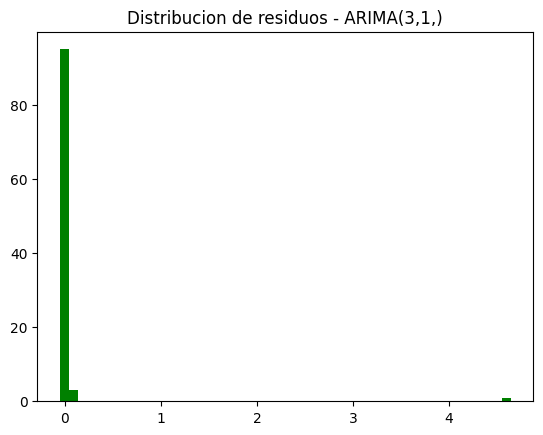

In [12]:
#Evaluo si los residuos son normales
print("==================================================")
print("==================================================")
print("Residuos modelo ARIMA(3,1,0)")
print("==================================================")
print("==================================================")
evaluar_jarque_bera(residuos_modelo_1, "ARIMA(3,1,0)")

plt.title("Distribucion de residuos - ARIMA(3,1,)")
plt.hist(residuos_modelo_1, bins=50, color='green')
plt.show()


Residuos modelo ARIMA(1,1,0)
Test de Jarque-Bera: ARIMA(1,1,0)
Estadístico JB : 37806.9395
p-valor        : 0.0000


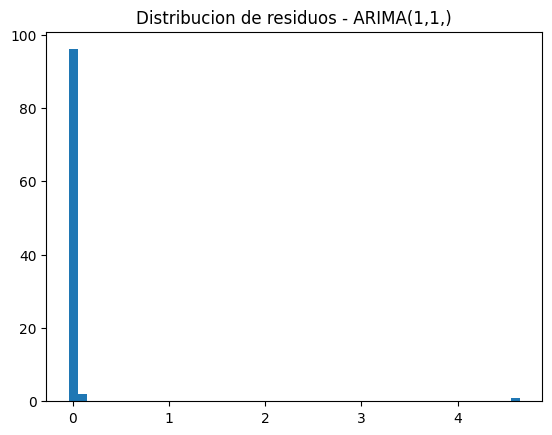

In [11]:
print("==================================================")
print("==================================================")
print("Residuos modelo ARIMA(1,1,0)")
print("==================================================")
print("==================================================")
evaluar_jarque_bera(residuos_modelo_2, "ARIMA(1,1,0)")

plt.title("Distribucion de residuos - ARIMA(1,1,)")
plt.hist(residuos_modelo_2, bins=50)
plt.show()

El test de Jarque-Bera arrojó un p-valor de 0.0000 para ambos modelos, rechazando la hipótesis de normalidad en los residuos. Este fenómeno es característico en series temporales de precios e inflación debido a la presencia de shocks exógenos y valores atípicos históricos.\
No obstante, dado que los residuos superaron satisfactoriamente el test de Ljung-Box (confirmando la ausencia de autocorrelación serial), la condición de ruido blanco se mantiene. En consecuencia, las propiedades de insesgadez y consistencia de los estimadores para la realización de pronósticos permanecen válidas, utilizándose aproximaciones asintóticas para la construcción de los intervalos de predicción\
La falta de normalidad afecta únicamente a la precisión teórica de los intervalos de confianza de las proyecciones a futuro, los cuales pasan a depender del Teorema del Límite Central (propiedades asintóticas para muestras grandes)